# Photoreceptor segmentation using [napari](https://napari.org/) and [cellpose](https://cellpose-napari.readthedocs.io/en/latest/index.html)

### Basic usage:
```python
viewer = napari.Viewer()
nbscreenshot(viewer)
viewer.close()
```

example notebooks [here](https://github.com/sofroniewn/napari-training-course/blob/master/lessons/)

In [2]:
# !mamba install -c conda-forge devbio-napari --yes
# !jupyter labextension list
# !mamba install -c conda-forge cellpose-napari --yes
# from cellpose import models

ModuleNotFoundError: No module named 'cellpose'

In [1]:
# image analysis
import napari
from magicgui import magicgui
from enum import Enum
import cellpose_napari
import cellpose
from cellpose import models
from tifffile import imread
import napari_nikon_nd2
from skimage.io import imread
from magicgui import magicgui
# python basics and plotting
import numpy as np
import pandas as pd
import math
from scipy import ndimage
from scipy.stats import kruskal
from scipy.stats import zscore
from scipy.stats import sem
import scikit_posthocs
import scipy.spatial
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import svgutils
from svgutils.compose import *
# system interaction
import os.path
import time, sys, warnings, re
from tqdm.notebook import tqdm, trange
import importlib
import ipywidgets
from IPython.display import display
# lab brews
from plotParams import *
from lloyd import *


def getFileList(dirData,gene,fileNameMatch,addDetails=''):
   fileList = sorted([f for f in os.listdir(dirData) if not f.startswith('.')]) # get all the files in the data directory (excluding system files) and sort them alphabatically
   fileList = ([f for f in fileList if gene in f]) # select files that match the gene of interest
   fileList = ([f for f in fileList if any([s in f for s in fileNameMatch])]) # only keep relevant files
   if (addDetails=='path'):
      fileList = (['# filePath = \'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\'; gene = \'' + gene + '\'; '), fileList)) #remove file extension (.nd2) and add text after each file
   elif (addDetails=='list'):
      fileList = (['\'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\','), fileList)) #remove file extension (.nd2) and add text after each file
   else:
      fileList = list(map(lambda st: str.replace(st, '.nd2', ''), fileList)) #remove file extension (.nd2) and add text after each file
   return fileList


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [3]:
applyPlotStyle(pBGMenu.value)
viewer = napari.Viewer()

Plotting style is Dark


In [143]:
viewer = napari.Viewer()

In [142]:
        viewer.close()

***
# Index <a id='Index'></a>
***
- [define directories](#dirDef)
- [Extraction of z planes for analysis](#zExtract)
- [Segmentation with cellpose](#cellSeg)
- [Manual correction of segmentation](#manualCuration)
- [Create thumbnails _WIP_](#thumbnails)
- [Quantification](#quantification)

***
## Define directories<a id='dirDefdirDef'>∮</a>
***
[Back to Index](#Index)

In [3]:
# define where all the imaging data is stored
dirData = 'Z:/AxR/20250425_2ahetinx_m2G_tdT/'
# define where all the analysis files should be stored
# subdirectories for each gene and transgenic lines need to be manually made first
dirAnalysis = "Z:/Analysis/20250425_2ahetinx_m2G_tdT/m2GtdT/"

# # define where all the imaging data is stored
# dirData = 'D:/Imaging/0250202_2bhetinx_s2C_m2G/'
# # define where all the analysis files should be stored
# # subdirectories for each gene and transgenic lines need to be manually made first
# dirAnalysis = 'D:/Analysis/20250202_Tbx2bhetinx_m2Gs2C/m2Gs2C/'

In [4]:
gene = '2ahetinx' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
# gene = 'lhx1a' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
fileNameMatch = ['002','004'] # characters in filenames that define zoom-in files

# get a list with all the relevant files
print(*getFileList(dirData,gene,fileNameMatch,addDetails='path'), sep = "\n") #display the file list for copy and paste below

# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_002'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_004'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_002'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_004'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_002'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_004'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L11_002'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L12_002'; gene = '2ahetinx'; 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L13_002'; gene = '2ahetinx'; 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002'; gene = '2ahetinx'; 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004'; gene = '2ahetinx'; 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002'; gene = '2ahetinx'; 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004'; gene = '2ahetinx'; 
# filePath = '20250425_5dpf_tbx

***
## Extract layers from z-stacks<a id='zExtract'>∮</a>
> Open z-stack &rarr; Pick limits in z for Maximum-Intensity Projection (_MIP_) &rarr; save MIPs &rarr; Ensure image was located in central retina
***
[Back to Index](#Index)

In [5]:
# clear viewer if needed
viewer.layers.select_all()
viewer.layers.remove_selected()

In [79]:
# clear viewer before any loading
viewer.layers.select_all()
viewer.layers.remove_selected()

# open files one by one (by commenting and uncommenting each one)

#hetinx 5 dpf
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_002'; gene = '2ahetinx'; # Tear in zoom in - OMIT
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_004'; gene = '2ahetinx'; zlims = [26, 29]; #normal 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_002'; gene = '2ahetinx'; zlims = [19, 21]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_004'; gene = '2ahetinx'; zlims = [16, 18]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_002'; gene = '2ahetinx'; zlims = [32, 43]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_004'; gene = '2ahetinx'; zlims = [25, 28]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L11_002'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L12_002'; gene = '2ahetinx'; zlims = [21, 27]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L13_002'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002'; gene = '2ahetinx'; zlims = [17, 20]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002'; gene = '2ahetinx'; # blurred - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004'; gene = '2ahetinx'; zlims = [25, 30]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002'; gene = '2ahetinx'; zlims = [28, 34]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004'; gene = '2ahetinx'; zlims = [18, 20]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002'; gene = '2ahetinx'; zlims = [29, 31]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004'; gene = '2ahetinx'; zlims = [20, 22]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002'; gene = '2ahetinx'; zlims = [8, 14]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004'; gene = '2ahetinx'; zlims = [24,29]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002'; gene = '2ahetinx'; zlims = [24,26]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002'; gene = '2ahetinx'; zlims = [15,17]; #normal
filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004'; gene = '2ahetinx';zlims = [17,19]; #normal 


# layerNames = ['R', 'U', 'N']
layerNames = ['M', 'L', 'PNA', 'N']
# layerNames = ['N', 'U']

# create subdirectory for analysis output
dirOut = dirAnalysis + gene + '/' + filePath + '/'
if (os.path.isdir(dirOut)==False):
   os.mkdir(dirOut)
   print('Created output directory')

print('Canvas cleared. Loading data...\n\n')

# load whole stack to figure out best z-planes for cellpose
viewer.open((dirData+filePath + '.nd2'), plugin='napari-nikon-nd2')
viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
if len(viewer.layers)==2: #no DAPI
   nChannels = 2
   viewer.layers[0].colormap = 'cyan'
   viewer.layers[0].name = layerNames[0]
   viewer.layers[1].colormap = 'magenta'
   viewer.layers[1].name = layerNames[1]
elif len(viewer.layers)==3: #DAPI
   nChannels = 3
   viewer.layers[0].colormap = 'cyan'
   viewer.layers[0].name = 'N'
   viewer.layers[0].opacity = 0.99
   viewer.layers[1].colormap = 'green'
   viewer.layers[1].name = layerNames[0]
   viewer.layers[2].colormap = 'magenta'
   viewer.layers[2].name = layerNames[1]
   layerNames.append('N')
elif len(viewer.layers)==4: #DAPI
   nChannels = 4
   viewer.layers[0].colormap = 'gray'
   viewer.layers[0].name = 'N'
   viewer.layers[0].opacity = 0.99
   viewer.layers[1].colormap = 'green'
   viewer.layers[1].name = layerNames[0]
   viewer.layers[2].colormap = 'magenta'
   viewer.layers[2].name = layerNames[1]
   viewer.layers[3].colormap = 'bop orange'
   viewer.layers[3].name = layerNames[2]
   layerNames.append('N')

print('Images loaded!')

Created output directory
Canvas cleared. Loading data...


Images loaded!


In [80]:
# make mips (and remove any previous ones) by defining the z-limits to use
zlims = [17,19];
if len(viewer.layers)>nChannels:
    for l in viewer.layers[nChannels:]:
      viewer.layers.remove(l)

for l in viewer.layers[0:nChannels]:
    l.visible = False
#     viewer.layers.remove(l.name + '_mip')
    viewer.add_image(l.data[zlims[0]:zlims[1]].max(axis=0), blending='additive', colormap = l.colormap, name = l.name + "_mip")

In [81]:
# SAVE in folder for batch cellpose analysis (when mips look good)
for name in layerNames:
   l = viewer.layers[name + '_mip']; l.save(dirOut + l.name + '.tiff')
print('MIP layers saved for ' + filePath)

MIP layers saved for 20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004


### Establish landmarks in whole-eye MIP
- Use eyeMarks layer to mark:
    - [ ] Landmark #1: Center of FOV (where zoom in is centered)
    - [ ] Landmark #2: Center of Optic Nerve Head 
    - [ ] Landmark #3: Dorsal edge of eye
    - [ ] Landmark #4: Ventral edge of eye
    - [ ] Landmark #5: Temporal edge of eye (strike zone side)
    - [ ] Landmark #6: Nasal edge of eye
- Decide if stack should be excluded (and stop analysis here and make note in csv summary file)

In [82]:
nMIP = len(layerNames)
for name in layerNames:
   lName = name + "_mip"
   viewer.layers[lName].scale = [1.5/8,1.5/8];
   viewer.layers[lName].translate = [0,+(512-1024*1.5/(8*2))]

# Load whole-eye MIP to establish landmarks
print('Loading eye mip...')
if str.endswith(filePath,'002'):
    mipPath = filePath[:-1] + '1_mip';
elif str.endswith(filePath,'004'):
    mipPath = filePath[:-1] + '3_mip';
elif str.endswith(filePath,'b'):
    mipPath = filePath[:-1] + 'a_mip';
elif str.endswith(filePath,'d'):
    mipPath = filePath[:-1] + 'c_mip';
viewer.open((dirData+mipPath + '.nd2'), plugin='napari-nikon-nd2', blending='additive')

viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
eyeChannels = 0
if len(viewer.layers)==2+nMIP+nChannels: # no DAPI, GFP and RFP
   eyeChannels = 2
   viewer.layers[nMIP+nChannels].colormap = 'green'
   viewer.layers[nMIP+nChannels].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
elif len(viewer.layers)==3+nMIP+nChannels: # leave DIC
   eyeChannels = 3
   viewer.layers[nMIP+nChannels+0].colormap = 'green'
   viewer.layers[nMIP+nChannels+0].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+2].colormap = 'gray'
   viewer.layers[nMIP+nChannels+2].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+2].opacity = 0.33
elif len(viewer.layers)==4+nMIP+nChannels: #DIC + DAPI
   eyeChannels = 4
   viewer.layers[nMIP+nChannels+0].colormap = 'gray'
   viewer.layers[nMIP+nChannels+0].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+1].colormap = 'green'
   viewer.layers[nMIP+nChannels+1].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+2].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+2].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+3].colormap = 'bop orange'
   viewer.layers[nMIP+nChannels+3].name = 'eyePNA'
   viewer.layers[nMIP+nChannels+3].opacity = 0.33
print(eyeChannels)
print('Loaded: ' + filePath)
eyeMarks = viewer.add_points(size=20, name = 'eyeMarks', symbol='cross', face_color='#ffffff80')
viewer.layers.select_next();

# Save eye landmarks
eyeMarksButton = ipywidgets.Button(description='Save eyeMarks', layout=ipywidgets.Layout(width='200px', height='100px'))
out = ipywidgets.Output()
def eyeMClick(_):
   with out:
      l = viewer.layers['eyeMarks']; l.save(dirOut + l.name + '.csv');
      print('eyeMarks layers saved for ' + filePath)
   # clear viewer
   viewer.layers.select_all()
   viewer.layers.remove_selected()
   eyeMarksButton.disabled = True # to prevent double clicking warnings. All sales are final!

eyeMarksButton.on_click(eyeMClick)

print('Make 6 landmark points then click button to save')

ipywidgets.VBox([eyeMarksButton,out])

Loading eye mip...
3
Loaded: 20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004
Make 6 landmark points then click button to save


### [Go back and run next one &uarr;](#zExtract)

***
## Segmentation using cellpose<a id='cellSeg'>∮</a>
> Define list of files to segment &rarr; Define cellpose parameters &rarr; Run cellpose in each image
***
[Back to Index](#Index)

### Running cellpose as batch analysis
Usually for:
- Rods: diameter = 20; flow_threshold = 0.5 and mask_threshold = 0.0
- Cones: diameter = 40; flow_threshold = 0.5 and mask_threshold = 0.0
- Horizontal cells: diameter = 100; flow_threshold = 0.6 and mask_threshold = 0.0

> Using a higher _flow_threshold_ (i.e. 0.6 instead of 0.4) will provide more ROIs

In [83]:
# get file list again
gene = '2ahetinx'
print(*getFileList(dirData,gene,fileNameMatch,addDetails='list'), sep = "\n") #display the file list for copy and paste below

'20250425_2ahetinx_5d_m2G_tdT_L08_002',
'20250425_2ahetinx_5d_m2G_tdT_L08_004',
'20250425_2ahetinx_5d_m2G_tdT_L09_002',
'20250425_2ahetinx_5d_m2G_tdT_L09_004',
'20250425_2ahetinx_5d_m2G_tdT_L10_002',
'20250425_2ahetinx_5d_m2G_tdT_L10_004',
'20250425_2ahetinx_5d_m2G_tdT_L11_002',
'20250425_2ahetinx_5d_m2G_tdT_L12_002',
'20250425_2ahetinx_5d_m2G_tdT_L13_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004',


In [84]:
# clear viewer
viewer.layers.select_all(); viewer.layers.remove_selected()

# collect file paths for uninjected
gene_wt = '2ahetinx'
filePaths_wt = [
# '20250425_2ahetinx_5d_m2G_tdT_L08_002', #tear in retina 
'20250425_2ahetinx_5d_m2G_tdT_L08_004',
'20250425_2ahetinx_5d_m2G_tdT_L09_002',
'20250425_2ahetinx_5d_m2G_tdT_L09_004',
'20250425_2ahetinx_5d_m2G_tdT_L10_002',
'20250425_2ahetinx_5d_m2G_tdT_L10_004',
# '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
'20250425_2ahetinx_5d_m2G_tdT_L12_002',
# '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002',
#'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
#'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002',
'20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004',
         ]



# define cellpose parameters
cpParams = {
    'model' : 'cyto2', # default is 'cyto' or 'cyto2'
    'net_avg' : True,
    'channels' : [0,0], #single channel without nucleus info
    'diameterR' : 25,
    'diameterC' : 40,
    'diameterH' : 100,
    'flow_threshold' : 0.5,
    'cellprob_threshold' : 0.0
}


# define model to use (e.g. 'cyto2')
model = models.Cellpose(gpu=False, model_type=cpParams['model'])

print('I have now defined the new files to run')

I have now defined the new files to run


#### Run in loop to track progress and automatically save results
> In Jan 2022: ~4 minutes per 1024 x 1024 image (4 nets). 

In [85]:
print('Starting analysis for '+ gene_wt + ':')
with tqdm(total=len(filePaths_wt)*len(layerNames), file=sys.stdout) as progBar:
   for fp in filePaths_wt:
      print('\t' + fp)
      for l in layerNames:
         print('\t\t ' + l)
         startTime = time.time()
         imgPath = dirAnalysis + gene_wt + '/' + fp + '/' + l + '_mip.tiff'
         img = cellpose.io.imread(imgPath)
         if l=='R':
            diameterCell = cpParams['diameterR']
         else:
            diameterCell = cpParams['diameterC']
         masks, flows, styles, diams = model.eval(img, 
                                                diameter=diameterCell, channels=cpParams['channels'],
                                                do_3D=False, net_avg = cpParams['net_avg'], interp = True,
                                                flow_threshold = cpParams['flow_threshold'], cellprob_threshold = cpParams['cellprob_threshold'])
         cellpose.io.masks_flows_to_seg(img, masks, flows, diams, imgPath, cpParams['channels']) # save results
         endTime = time.time()
         print ('\t Time elapsed: {elapsedTime} s\n'.format(elapsedTime = int(endTime - startTime)))
         progBar.update(1)

print('Finished cellpose batch analysis for '+ gene_wt)

# print('Starting analysis for '+ gene_F0 + ':')
# with tqdm(total=len(filePaths_F0)*len(layerNames), file=sys.stdout) as progBar:
#    for fp in filePaths_F0:
#       print('\t' + fp)
#       for l in layerNames:
#          print('\t\t ' + l)
#          startTime = time.time()
#          imgPath = dirAnalysis + gene_F0 + '/' + fp + '/' + l + '_mip.tiff'
#          img = cellpose.io.imread(imgPath)
#          if l=='R':
#             diameterCell = cpParams['diameterR']
#          else:
#             diameterCell = cpParams['diameterC']
#          masks, flows, styles, diams = model.eval(img, 
#                                                 diameter=diameterCell, channels=cpParams['channels'],
#                                                 do_3D=False, net_avg = cpParams['net_avg'], interp = True,
#                                                 flow_threshold = cpParams['flow_threshold'], cellprob_threshold = cpParams['cellprob_threshold'])
#          cellpose.io.masks_flows_to_seg(img, masks, flows, diams, imgPath, cpParams['channels']) # save results
#          endTime = time.time()
#          print ('\t\t\t Time elapsed: {elapsedTime} s'.format(elapsedTime = int(endTime - startTime)))
#          progBar.update(1)

# print('Finished cellpose batch analysis for '+ gene_F0)

Starting analysis for 2ahetinx:


  0%|          | 0/85 [00:00<?, ?it/s]

	20250425_2ahetinx_5d_m2G_tdT_L08_004
		 M
	 Time elapsed: 51 s

		 L
	 Time elapsed: 38 s

		 PNA
	 Time elapsed: 39 s

		 N
	 Time elapsed: 39 s

		 N
	 Time elapsed: 39 s

	20250425_2ahetinx_5d_m2G_tdT_L09_002
		 M
	 Time elapsed: 47 s

		 L
	 Time elapsed: 38 s

		 PNA
	 Time elapsed: 37 s

		 N
	 Time elapsed: 37 s

		 N
	 Time elapsed: 37 s

	20250425_2ahetinx_5d_m2G_tdT_L09_004
		 M
	 Time elapsed: 42 s

		 L
	 Time elapsed: 37 s

		 PNA
	 Time elapsed: 37 s

		 N
	 Time elapsed: 37 s

		 N
	 Time elapsed: 37 s

	20250425_2ahetinx_5d_m2G_tdT_L10_002
		 M
	 Time elapsed: 45 s

		 L
	 Time elapsed: 36 s

		 PNA
	 Time elapsed: 44 s

		 N
	 Time elapsed: 37 s

		 N
	 Time elapsed: 38 s

	20250425_2ahetinx_5d_m2G_tdT_L10_004
		 M
	 Time elapsed: 48 s

		 L
	 Time elapsed: 36 s

		 PNA
	 Time elapsed: 39 s

		 N
	 Time elapsed: 37 s

		 N
	 Time elapsed: 38 s

	20250425_2ahetinx_5d_m2G_tdT_L12_002
		 M
	 Time elapsed: 60 s

		 L
	 Time elapsed: 36 s

		 PNA
	 Time elapsed: 55 s

		 N

***
## Manual correction of cellpose segmentation<a id='manualCuration'>∮</a>
> Copy file list from "Extract Layers" &rarr; Open a single file and manually fix ("_curate_") cellpose segmentation

WARNINGS:
- In tg[_mws2_:GFP], a subset of S cones are GFP+. If available, use tg[_sws2_:mCherry] to delete those labels from the M-cone segmentation
***
[Back to Index](#Index)

In [6]:
# clear viewer
viewer.layers.select_all(); viewer.layers.remove_selected()

#hetinx 5 dpf
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_002'; gene = '2ahetinx'; # Tear in zoom in - OMIT
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L08_004'; gene = '2ahetinx'; zlims = [26, 29]; #normal 
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_002'; gene = '2ahetinx'; zlims = [19, 21]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L09_004'; gene = '2ahetinx'; zlims = [16, 18]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_002'; gene = '2ahetinx'; zlims = [32, 43]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L10_004'; gene = '2ahetinx'; zlims = [25, 28]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L11_002'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L12_002'; gene = '2ahetinx'; zlims = [21, 27]; #normal
# filePath = '20250425_2ahetinx_5d_m2G_tdT_L13_002'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002'; gene = '2ahetinx'; zlims = [17, 20]; #EXCLUDE = WEIRD DARK SPOT BLOCKING SIGNAL normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004'; gene = '2ahetinx'; #too curved - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002'; gene = '2ahetinx'; # blurred - OMIT
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004'; gene = '2ahetinx'; zlims = [25, 30]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002'; gene = '2ahetinx'; zlims = [28, 34]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004'; gene = '2ahetinx'; zlims = [18, 20]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002'; gene = '2ahetinx'; zlims = [29, 31]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004'; gene = '2ahetinx'; zlims = [20, 22]; #normal
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002'; gene = '2ahetinx'; zlims = [8, 14]; #normal #not a good flat zoom in
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004'; gene = '2ahetinx'; zlims = [24,29]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002'; gene = '2ahetinx'; zlims = [24,26]; #normal 
# filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002'; gene = '2ahetinx'; zlims = [15,17]; #normal
filePath = '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004'; gene = '2ahetinx';zlims = [17,19]; #normal 

# Analysis completed: 07/22/2025

# define subdirectory for analysis
dirOut = dirAnalysis + gene + '/' + filePath + '/'
print('Viewer cleared...')

# clear key binds
@viewer.bind_key('k', overwrite=True)
def toggle_sel(viewer):
    ...
@viewer.bind_key('b', overwrite=True)
def toggle_sel(viewer):
    ...
@viewer.bind_key('Shift-x', overwrite=True)
def removeLabel(viewer):
    ...

# load mips
mipO = 0.65
viewer.open(dirOut + layerNames[0] + "_mip.tiff", plugin='napari', colormap = 'green', blending='additive', opacity=mipO);
viewer.open(dirOut + layerNames[1] + "_mip.tiff", plugin='napari', colormap = 'magenta', blending='additive', opacity=mipO);
# viewer.open(dirOut + layerNames[2] + "_mip.tiff", plugin='napari', colormap = 'gray', blending='additive', opacity=mipO);

# load segmentation
if (os.path.isfile(dirOut + layerNames[0] + "_seg_curated.tiff")):
    print('Loaded previously curated segmentation for {0}'.format(layerNames[0]))
    viewer.open(dirOut + layerNames[0] + "_seg_curated.tiff", name=layerNames[0] + '_seg', plugin='napari',blending='additive');
else:
    segData = np.load(dirOut + layerNames[0] + "_mip" + "_seg.npy", allow_pickle=True).item()
    viewer.add_labels(segData['masks'], name= layerNames[0] + '_seg',blending='additive');
viewer.layers[layerNames[0] + '_seg'].preserve_labels = True;

if (os.path.isfile(dirOut + layerNames[1] + "_seg_curated.tiff")):
    print('Loaded previously curated segmentation for {0}'.format(layerNames[1]))
    viewer.open(dirOut + layerNames[1] + "_seg_curated.tiff", name=layerNames[1] + '_seg', plugin='napari',blending='additive');
else:
    segData = np.load(dirOut + layerNames[1] + "_mip" + "_seg.npy", allow_pickle=True).item()
    viewer.add_labels(segData['masks'], name= layerNames[1] + '_seg',blending='additive');
viewer.layers[layerNames[1] + '_seg'].preserve_labels = True;


viewer.layers[layerNames[0] + '_mip'].visible = False
# viewer.layers[layerNames[3] + '_mip'].visible = False
viewer.layers[layerNames[0] + '_seg'].visible = False

print('Loaded  ' + filePath + ' !\n Now fix it and save it!')

#define useful keyboard shortcuts

@viewer.bind_key('Shift-x', overwrite=True)
def removeLabel(viewer):
   lname = layerNames[1] + '_seg'
   tempd = viewer.layers[lname].data
   tempd[tempd == viewer.layers[lname].selected_label]=0
   viewer.layers[lname].data = tempd
   print('Cut!')
print('removeLabel on {0}_seg ("Shift-X")'.format(layerNames[1]))

@viewer.bind_key('k', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[1] + '_seg'
   if (viewer.layers[lname].preserve_labels == True):
      viewer.layers[lname].preserve_labels = False
   elif (viewer.layers[lname].preserve_labels == False):
      viewer.layers[lname].preserve_labels = True
print('toggle {0}_seg preserve_labels ("k")'.format(layerNames[1]))
        
@viewer.bind_key('b', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[1] + '_mip'
   if (viewer.layers[lname].visible == True):
      viewer.layers[lname].visible = False
   elif (viewer.layers[lname].visible == False):
      viewer.layers[lname].visible = True
print('toggle {0}_mip visibility ("B")'.format(layerNames[1]))

@viewer.bind_key('n', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[0] + '_mip'
   if (viewer.layers[lname].visible == True):
      viewer.layers[lname].visible = False
   elif (viewer.layers[lname].visible == False):
      viewer.layers[lname].visible = True
print('toggle {0}_mip visibility ("N")'.format(layerNames[0]))

@viewer.bind_key('+', overwrite=True)
def new_label(viewer):
   """Set the currently selected label to the largest used label plus one."""
   lname = layerNames[1] + '_seg'
   viewer.layers[lname].selected_label = viewer.layers[lname].data.max() + 1
print('Add new label in {0}_seg visibility ("+"|"M")'.format(layerNames[1]))

Viewer cleared...
Loaded previously curated segmentation for M
Loaded previously curated segmentation for L
Loaded  20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004 !
 Now fix it and save it!
removeLabel on L_seg ("Shift-X")
toggle L_seg preserve_labels ("k")
toggle L_mip visibility ("B")
toggle M_mip visibility ("N")
Add new label in L_seg visibility ("+"|"M")


In [73]:
# if needed, run this cell to reload whole z-stack
print('Loading data...')
nMIP = len(viewer.layers)
viewer.open((dirData+filePath + '.nd2'), plugin='napari-nikon-nd2')
viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
if len(viewer.layers)==2+nMIP: #no DAPI
   viewer.layers[nMIP+0].colormap = 'green'
   viewer.layers[nMIP+0].name = layerNames[0]
   viewer.layers[nMIP+1].colormap = 'magenta'
   viewer.layers[nMIP+1].name = layerNames[1]
elif len(viewer.layers)==3+nMIP: #DAPI
   viewer.layers[nMIP+0].colormap = 'gray'
   viewer.layers[nMIP+0].name = 'N'
   viewer.layers[nMIP+0].opacity = 0.99
   viewer.layers[nMIP+1].colormap = 'green'
   viewer.layers[nMIP+1].name = layerNames[0]
   viewer.layers[nMIP+2].colormap = 'magenta'
   viewer.layers[nMIP+2].name = layerNames[1]
elif len(viewer.layers)==4+nMIP: #DAPI
   viewer.layers[nMIP+0].colormap = 'gray'
   viewer.layers[nMIP+0].name = 'N'
   viewer.layers[nMIP+0].opacity = 0.99
   viewer.layers[nMIP+1].colormap = 'green'
   viewer.layers[nMIP+1].name = layerNames[0]
   viewer.layers[nMIP+2].colormap = 'magenta'
   viewer.layers[nMIP+2].name = layerNames[1]
   viewer.layers[nMIP+3].colormap = 'bop orange'
   viewer.layers[nMIP+3].name = layerNames[2]

print('Images loaded!')

Loading data...
Images loaded!


#### resave first curated segmentation after napari-ing around

In [146]:
lname = layerNames[1] + '_seg'
l = viewer.layers[lname]; l.save(dirOut + l.name + '_curated.tiff')
print('Done with ' + lname + ' for ' + filePath)

viewer.layers[layerNames[0] + '_mip'].visible = True
viewer.layers[layerNames[0] + '_seg'].visible = True
# viewer.layers[layerNames[0] + '_seg'].contour = 0
viewer.layers[layerNames[1] + '_mip'].visible = False
viewer.layers[layerNames[1] + '_seg'].visible = False

@viewer.bind_key('Shift-x', overwrite=True)
def removeLabel(viewer):
   lname = layerNames[0] + '_seg'
   tempd = viewer.layers[lname].data
   tempd[tempd == viewer.layers[lname].selected_label]=0
   viewer.layers[lname].data = tempd
   print('Cut!')
print('removeLabel on {0}_seg ("Shift-X")'.format(layerNames[0]))

@viewer.bind_key('b', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[1] + '_mip'
   if (viewer.layers[lname].visible == True):
      viewer.layers[lname].visible = False
   elif (viewer.layers[lname].visible == False):
      viewer.layers[lname].visible = True
print('toggle {0}_mip visibility ("B")'.format(layerNames[1]))

@viewer.bind_key('n', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[0] + '_mip'
   if (viewer.layers[lname].visible == True):
      viewer.layers[lname].visible = False
   elif (viewer.layers[lname].visible == False):
      viewer.layers[lname].visible = True
print('toggle {0}_mip visibility ("N")'.format(layerNames[0]))


@viewer.bind_key('k', overwrite=True)
def toggle_sel(viewer):
   lname = layerNames[0] + '_seg'
   if (viewer.layers[lname].preserve_labels == True):
      viewer.layers[lname].preserve_labels = False
   elif (viewer.layers[lname].preserve_labels == False):
      viewer.layers[lname].preserve_labels = True
print('toggle {0}_seg preserve_labels ("k")'.format(layerNames[0]))

@viewer.bind_key('+', overwrite=True)
def new_label(viewer):
   """Set the currently selected label to the largest used label plus one."""
   lname = layerNames[0] + '_seg'
   viewer.layers[lname].selected_label = viewer.layers[lname].data.max() + 1
print('Add new label in {0}_seg visibility ("+"|"M")'.format(layerNames[0]))

Done with L_seg for 20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004
removeLabel on M_seg ("Shift-X")
toggle L_mip visibility ("B")
toggle M_mip visibility ("N")
toggle M_seg preserve_labels ("k")
Add new label in M_seg visibility ("+"|"M")


#### resave second curated segmentation after napari-ing around

In [147]:
lname = layerNames[0] + '_seg'
l = viewer.layers[lname]; l.save(dirOut + l.name + '_curated.tiff')
print('Done with ' + lname + ' for ' + filePath)


Done with M_seg for 20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004


### Reload curated segmentations after saving for final review

In [148]:
# remove all except mips
viewer.layers.remove(viewer.layers[layerNames[1] + '_seg'])
viewer.layers.remove(viewer.layers[layerNames[0] + '_seg'])

viewer.open(dirOut + layerNames[1] + "_seg_curated.tiff", name=layerNames[1] + '_seg', plugin='napari',blending='additive');
# viewer.layers['U_seg'].contour = 5
viewer.layers[layerNames[1] + '_mip'].visible = True
viewer.open(dirOut + layerNames[0] + '_seg_curated.tiff', name=layerNames[0] + '_seg', plugin='napari',blending='additive');

print(filePath)
n0 = len(np.unique(viewer.layers[layerNames[1] + '_seg'].data))-1
print("Image has {0} {1}".format(n0, layerNames[1]))
n1 = len(np.unique(viewer.layers[layerNames[0] + '_seg'].data))-1
print("Image has {0} {1}".format(n1,layerNames[0]))

20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004
Image has 300 L
Image has 242 M


### [Go back and run next one &uarr;](#manualCuration)

***
## Quantification: GFP inside L cones<a id='quantification'>∮</a>
***
[Back to Index](#Index)

Plan (loosely based on Mander's coefficient):
1. Erode S cone segmentation to focus on center of cells
2. Divide GFP fluorescence into millies as a way to normalize data between images into 0 - 1000 range
3. Calculate for each cone what normalized average fluorescence corresponds too.

Questions:
1. How much erosion?
2. Do I have to exclude S cones to do GFP percentile calculation? &rarr; this would assume that GFP outside L cones is unchanged, which could be tested|plotted directly.
3. Also check if RFP distributions are unchanged?

In [13]:
# erosionValue = 27 #Ran on all samples 5/5/26
erosionValue = 32 #already better
viewer.layers['L_seg_curated'].data = ndimage.grey_erosion(viewer.layers['L_seg_curated'].data, size=(erosionValue,erosionValue))

In [3]:
def calcMillie(viewer,lname):
    outHist,outBins = np.histogram(viewer.layers[lname].data.flatten(), bins = 1000)
    return outHist,outBins

def GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=10):
    # clear viewer
    for l in viewer.layers:
        viewer.layers.remove(l)
    viewer.layers.select_all()
    viewer.layers.remove_selected()
    dOut = dAnalysis + gene + '/' + fPath + '/'
    print('Quantifying GFP in L cones of ' + fPath + '(' + gene + ')\n')
    # load mips
    viewer.open(dOut + 'M' + "_mip.tiff", plugin='builtins', colormap = 'green', blending='additive');
    viewer.open(dOut + 'L' + "_mip.tiff", plugin='builtins', colormap = 'magenta', blending='additive');
    # viewer.open(dOut + 'M' + "_seg_curated_incomplete.tiff", name='M_seg', plugin='builtins', blending='additive');
    viewer.open(dOut + 'L' + "_seg_curated.tiff", name='L_seg', plugin='builtins', blending='additive');
    # viewer.layers['M_seg'].preserve_labels = True;
    viewer.layers['L_seg'].preserve_labels = True;
    viewer.layers['L_seg'].contour = 5
    # erode L cone segmentation
    viewer.layers['L_seg'].data = ndimage.grey_erosion(viewer.layers['L_seg'].data, size=(erosionValue,erosionValue))
    # divide images into 1000 bins
    mH, mB = calcMillie(viewer,'M_mip')
    lH, lB = calcMillie(viewer,'L_mip')

    lcones = np.unique(viewer.layers['L_seg'].data)
    lcones = lcones[lcones>0]
    lRFP = np.empty(np.shape(lcones))
    lGFP = np.empty(np.shape(lcones))
    lRFPsd = np.empty(np.shape(lcones))
    lGFPsd = np.empty(np.shape(lcones))
    lRtile = np.empty(np.shape(lcones))
    lGtile = np.empty(np.shape(lcones))
    
    i=0;
    for l in lcones:
        lRFP[i] = np.mean(viewer.layers['L_mip'].data[viewer.layers['L_seg'].data==l])
        lGFP[i] = np.mean(viewer.layers['M_mip'].data[viewer.layers['L_seg'].data==l])
        lRFPsd[i] = np.std(viewer.layers['L_mip'].data[viewer.layers['L_seg'].data==l])
        lGFPsd[i] = np.std(viewer.layers['M_mip'].data[viewer.layers['L_seg'].data==l])
        lRtile[i] = len(lB[lB<lRFP[i]])
        lGtile[i] = len(mB[mB<lGFP[i]])
        i=i+1;
        
    np.savez(dOut + 'quantificationGFP.npz',
             lcones=lcones,
             lRFP=lRFP,
             lGFP=lGFP,
             lRFPsd=lRFPsd,
             lGFPsd=lGFPsd,
             lRtile=lRtile,
             lGtile=lGtile)
    results = zip(['lcones','lRFP','lGFP','lRFPsd','lGFPsd','lRtile','lGtile'],
                 [lcones,lRFP,lGFP,lRFPsd,lGFPsd,lRtile,lGtile])
    
    return results

## Test Cell for increasing GFP erosion 

> Previous ran erosion at 10-12 on segmentation files. Does not seem sufficient to show phenotype. 

> Juan ran erosion on a scope with a resolution half of the AXR - need to bump it to 18-20? 

In [30]:
erodeV = 27; #Test on hard mutant files

# analysis directory
dAnalysis = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"

# open file

# gene = 'wt'
# wt_fPaths = [# '20250425_2ahetinx_5d_m2G_tdT_L08_002', #tear in retina 
#                 '20250425_2ahetinx_5d_m2G_tdT_L08_004',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_002',
#                 '20250425_2ahetinx_5d_m2G_tdT_L09_004',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_002',
#                 '20250425_2ahetinx_5d_m2G_tdT_L10_004',
#                 # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
#                 '20250425_2ahetinx_5d_m2G_tdT_L12_002',
#                 # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
#                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
#                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
#                 #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004',
#                 # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002',
#                 '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004',
#                 '220250818_5d_2ahetinx_tdT_m2G_L01_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L02_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L03_002',
#                  '220250818_5d_2ahetinx_tdT_m2G_L05_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L05_004',
#                 '220250818_5d_2ahetinx_tdT_m2G_L06_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L07_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L08_004',
#                 '220250818_5d_2ahetinx_tdT_m2G_L010_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_002',
#                 '220250818_5d_2ahetinx_tdT_m2G_L011_006',
#                 # '220250817_5d_m2G_tdT_2ahetinx_L12_002', #mip not found
#                 '220250817_5d_m2G_tdT_2ahetinx_L12_006',
#                 '220250817_5d_m2G_tdT_2ahetinx_L13_002',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_002',
#                 '220250817_5d_m2G_tdT_2ahetinx_L14_006',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
#                # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_002', 
#                 '220250723_2bhetinx_5d_tdT_m2G_L03_004',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_002',
#                 '220250723_2bhetinx_5d_tdT_m2G_L04_004',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L06_002', #holes
#                 # '220250723_2bhetinx_5d_tdT_m2G_L06_004', #holes
#                 # '220250723_2bhetinx_5d_tdT_m2G_L08_002', #curved
#                 '220250723_2bhetinx_5d_tdT_m2G_L08_004',
#                 '220250723_2bhetinx_5d_tdT_m2G_L09_002',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L09_004', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L13_002', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L14_002', #curved
#                 '220250723_2bhetinx_5d_tdT_m2G_L14_004',
#                 # '220250723_2bhetinx_5d_tdT_m2G_L15_004', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L16_002', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L16_004', #curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
#                 # '220250723_2bhetinx_5d_tdT_m2G_L23_002', no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L23_004', no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L24_002', no l seg curated
#                 # '220250723_2bhetinx_5d_tdT_m2G_L25_002', #no m mip
#                 '220250723_2bhetinx_5d_tdT_m2G_L25_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L08_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L09_002',
#                 '20251017_5d_2bhetinx_tdT_m2G_L09_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L10_002',
#                 '20251017_5d_2bhetinx_tdT_m2G_L10_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L11_002',
#                 '20251017_5d_2bhetinx_tdT_m2G_L11_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L12_002',
#                 '20251017_5d_2bhetinx_tdT_m2G_L12_004',
#                 '20251017_5d_2bhetinx_tdT_m2G_L14_002',
#                 '20251017_5d_2bhetinx_tdT_m2G_L14_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L01_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L01_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L02_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L02_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L03_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L05_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L05_004',
#                 # '20251022_5d_2bhetinx_m2G_tdT_L06_002', #omit too curved :( 
#                 '20251022_5d_2bhetinx_m2G_tdT_L07_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L15_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L15_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L16_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L16_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L17_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L17_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L19_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L19_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L20_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L20_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L21_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L22_002',
#                 '20251022_5d_2bhetinx_m2G_tdT_L22_004',
#                 '20251022_5d_2bhetinx_m2G_tdT_L28_002',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_002', #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004_mip',
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L30_002',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_002', #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_004', #redo GFP Quant Analysis 
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L35_002',
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_002', #redo GFP Quant Analysis 
#                 # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_004', #MIP didn't save - COMEBACK?!?!
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L37_002',
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L39_002',
#                 '20251022_5d_tbx2bhetinx_m2G_tdT_L40_002',
#                 '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_002',
#                 '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_004',
#                 '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_002',
#                 '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_004',
#          ]
# for fPath in wt_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)
    
# # tbx2a KO
# gene = 'Tbx2aKO';
# tbx2a_fPaths = [
#         '220250818_5d_2ahetinx_tdT_m2G_L04_002',
#     '220250818_5d_2ahetinx_tdT_m2G_L09_002',
#     '220250818_5d_2ahetinx_tdT_m2G_L09_006',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002',
#     '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004',
#                ]
# for fPath in tbx2a_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

# tbx2b KO
gene = 'Tbx2bKO';
tbx2b_fPaths = [
                # '220250723_2bhetinx_5d_tdT_m2G_L07_002',
                # # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved
                #  # '220250723_2bhetinx_5d_tdT_m2G_L26_004', #no curated l seg
                # '220250723_2bhetinx_5d_tdT_m2G_L26_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L27_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L28_002',
                # '20251022_5d_2bhetinx_m2G_tdT_L24_002',
                # '20251022_5d_2bhetinx_m2G_tdT_L24_004',
                # '20251022_5d_2bhetinx_m2G_tdT_L26_002',
                # '20251022_5d_2bhetinx_m2G_tdT_L26_004',
                # '20251022_5d_2bhetinx_m2G_tdT_L18_002',
                # '20251022_5d_2bhetinx_m2G_tdT_L18_004',
                # # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze
                # # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze
                # # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004',
               ]

for fPath in tbx2b_fPaths:
    GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
    for l in viewer.layers:
        viewer.layers.remove(l)

print('Finished analysis')

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 20251022_5d_tbx2bhetinx_m2G_tdT_L38_002(Tbx2bKO)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Finished analysis


GFP threshold is 0.205
# cells of bright GFP cells: wt=4.602254312362707, tbx2a=22.675086107921928, tbx2b=7.314090019569472


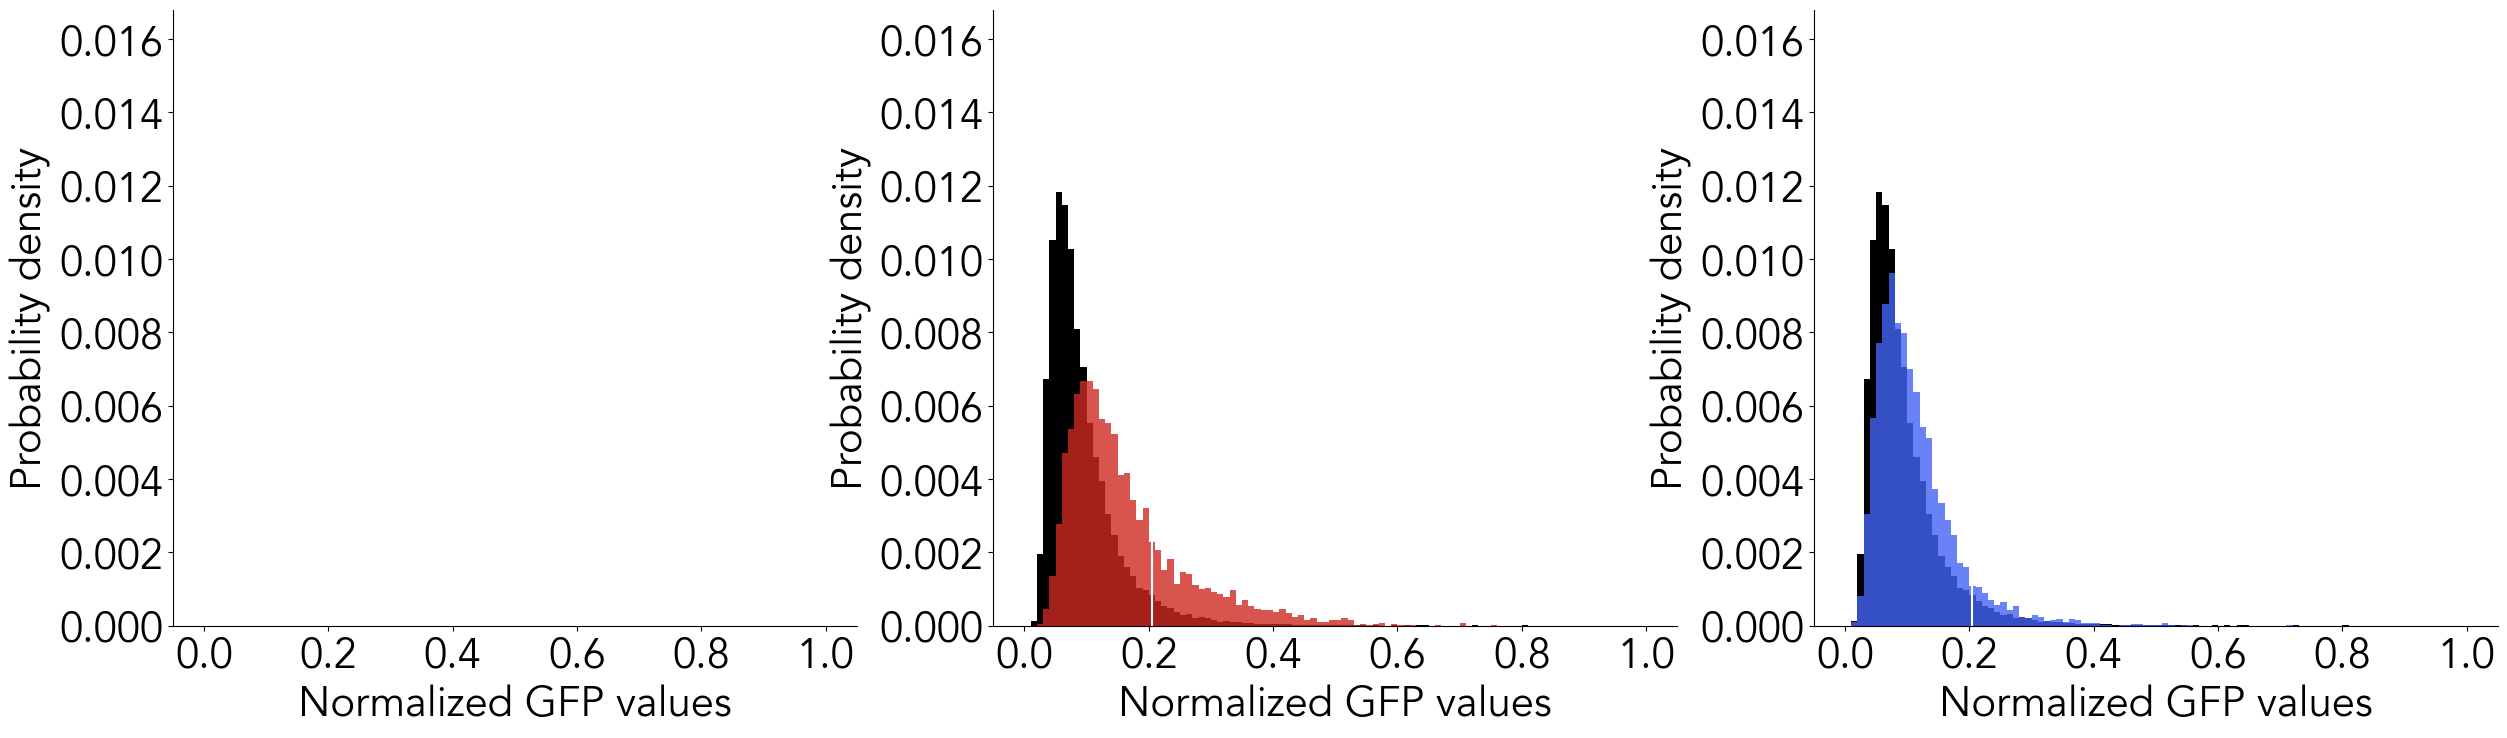

In [4]:
### After establishing threshold based on all data, count number of cells exceeding threshold for each eye# collect all results

# analysis directory
dAnalysis = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"

#OpenFile

gene = 'wt'
wt_fPaths = [# '20250425_2ahetinx_5d_m2G_tdT_L08_002', #tear in retina 
                '20250425_2ahetinx_5d_m2G_tdT_L08_004',
                '20250425_2ahetinx_5d_m2G_tdT_L09_002',
                '20250425_2ahetinx_5d_m2G_tdT_L09_004',
                '20250425_2ahetinx_5d_m2G_tdT_L10_002',
                '20250425_2ahetinx_5d_m2G_tdT_L10_004',
                # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
                '20250425_2ahetinx_5d_m2G_tdT_L12_002',
                # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004',
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004',
                '220250818_5d_2ahetinx_tdT_m2G_L01_002',
                '220250818_5d_2ahetinx_tdT_m2G_L02_002',
                '220250818_5d_2ahetinx_tdT_m2G_L03_002',
                 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
                '220250818_5d_2ahetinx_tdT_m2G_L05_004',
                '220250818_5d_2ahetinx_tdT_m2G_L06_002',
                '220250818_5d_2ahetinx_tdT_m2G_L07_002',
                '220250818_5d_2ahetinx_tdT_m2G_L08_002',
                '220250818_5d_2ahetinx_tdT_m2G_L08_004',
                '220250818_5d_2ahetinx_tdT_m2G_L010_002',
                '220250818_5d_2ahetinx_tdT_m2G_L011_002',
                '220250818_5d_2ahetinx_tdT_m2G_L011_006',
                # '220250817_5d_m2G_tdT_2ahetinx_L12_002', #mip not found
                '220250817_5d_m2G_tdT_2ahetinx_L12_006',
                '220250817_5d_m2G_tdT_2ahetinx_L13_002',
                '220250817_5d_m2G_tdT_2ahetinx_L14_002',
                '220250817_5d_m2G_tdT_2ahetinx_L14_006',
                # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
               # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L03_002', 
                '220250723_2bhetinx_5d_tdT_m2G_L03_004',
                '220250723_2bhetinx_5d_tdT_m2G_L04_002',
                '220250723_2bhetinx_5d_tdT_m2G_L04_004',
                # '220250723_2bhetinx_5d_tdT_m2G_L06_002', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L06_004', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L08_002', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L08_004',
                '220250723_2bhetinx_5d_tdT_m2G_L09_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L09_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L13_002', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L14_002', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L14_004',
                # '220250723_2bhetinx_5d_tdT_m2G_L15_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_002', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L23_002', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L23_004', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L24_002', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L25_002', #no m mip
                '220250723_2bhetinx_5d_tdT_m2G_L25_004',
                '20251017_5d_2bhetinx_tdT_m2G_L08_004',
                '20251017_5d_2bhetinx_tdT_m2G_L09_002',
                '20251017_5d_2bhetinx_tdT_m2G_L09_004',
                '20251017_5d_2bhetinx_tdT_m2G_L10_002',
                '20251017_5d_2bhetinx_tdT_m2G_L10_004',
                '20251017_5d_2bhetinx_tdT_m2G_L11_002',
                '20251017_5d_2bhetinx_tdT_m2G_L11_004',
                '20251017_5d_2bhetinx_tdT_m2G_L12_002',
                '20251017_5d_2bhetinx_tdT_m2G_L12_004',
                '20251017_5d_2bhetinx_tdT_m2G_L14_002',
                '20251017_5d_2bhetinx_tdT_m2G_L14_004',
                '20251022_5d_2bhetinx_m2G_tdT_L01_002',
                '20251022_5d_2bhetinx_m2G_tdT_L01_004',
                '20251022_5d_2bhetinx_m2G_tdT_L02_002',
                '20251022_5d_2bhetinx_m2G_tdT_L02_004',
                '20251022_5d_2bhetinx_m2G_tdT_L03_002',
                '20251022_5d_2bhetinx_m2G_tdT_L05_002',
                '20251022_5d_2bhetinx_m2G_tdT_L05_004',
                # '20251022_5d_2bhetinx_m2G_tdT_L06_002', #omit too curved :( 
                '20251022_5d_2bhetinx_m2G_tdT_L07_002',
                '20251022_5d_2bhetinx_m2G_tdT_L15_002',
                '20251022_5d_2bhetinx_m2G_tdT_L15_004',
                '20251022_5d_2bhetinx_m2G_tdT_L16_002',
                '20251022_5d_2bhetinx_m2G_tdT_L16_004',
                '20251022_5d_2bhetinx_m2G_tdT_L17_002',
                '20251022_5d_2bhetinx_m2G_tdT_L17_004',
                '20251022_5d_2bhetinx_m2G_tdT_L19_002',
                '20251022_5d_2bhetinx_m2G_tdT_L19_004',
                '20251022_5d_2bhetinx_m2G_tdT_L20_002',
                '20251022_5d_2bhetinx_m2G_tdT_L20_004',
                '20251022_5d_2bhetinx_m2G_tdT_L21_002',
                '20251022_5d_2bhetinx_m2G_tdT_L22_002',
                '20251022_5d_2bhetinx_m2G_tdT_L22_004',
                '20251022_5d_2bhetinx_m2G_tdT_L28_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004_mip',
                '20251022_5d_tbx2bhetinx_m2G_tdT_L30_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_004', #redo GFP Quant Analysis 
                '20251022_5d_tbx2bhetinx_m2G_tdT_L35_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_004', #MIP didn't save - COMEBACK?!?!
                '20251022_5d_tbx2bhetinx_m2G_tdT_L37_002',
                '20251022_5d_tbx2bhetinx_m2G_tdT_L39_002',
                '20251022_5d_tbx2bhetinx_m2G_tdT_L40_002',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_002',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_004',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_002',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_004',
                
         ]
# tbx2a
gene = 'Tbx2aKO';
tbx2a_fPaths = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002',
    '220250818_5d_2ahetinx_tdT_m2G_L09_002',
    '220250818_5d_2ahetinx_tdT_m2G_L09_006',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004',
               ]
# tbx2b
gene = 'Tbx2bKO';
tbx2b_fPaths = [
                '220250723_2bhetinx_5d_tdT_m2G_L07_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
                 # '220250723_2bhetinx_5d_tdT_m2G_L26_004', #no curated l seg
                '220250723_2bhetinx_5d_tdT_m2G_L26_002',
                '220250723_2bhetinx_5d_tdT_m2G_L27_002',
                '220250723_2bhetinx_5d_tdT_m2G_L28_002',
                '20251022_5d_2bhetinx_m2G_tdT_L24_002',
                '20251022_5d_2bhetinx_m2G_tdT_L24_004',
                '20251022_5d_2bhetinx_m2G_tdT_L26_002',
                '20251022_5d_2bhetinx_m2G_tdT_L26_004', #kinda curved 
                '20251022_5d_2bhetinx_m2G_tdT_L18_002',
                '20251022_5d_2bhetinx_m2G_tdT_L18_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat. 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
                '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #CURVED - stretched effect -  omit from analyzed data (CH 2026)
               ]
                
                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = 'wt'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    wtResults.append(results[rName])
    i=i+1;

aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = 'Tbx2aKO'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    aResults.append(results[rName])
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = 'Tbx2bKO'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    bResults.append(results[rName])
    i=i+1;


# combine across images
wtResults = np.concatenate(wtResults).ravel()
aResults = np.concatenate(aResults).ravel()
bResults = np.concatenate(bResults).ravel()

# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);

print('GFP threshold is {0}'.format(wt95CI))


baseColor='#000000'
# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, (axH1,axH2,axH3) = plt.subplots(nrows=1, ncols=3, figsize=(30, 8))
axH1.stairs(wtH,wtB/1000, fill=True, color = 'White', alpha = 1.0)
axH2.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH3.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = 0.8)
axH3.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = 0.8)


axH1.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)
axH2.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)
axH3.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)


# axH.set_title('Distribution of GFP inside L cones')
for axH in (axH1,axH2,axH3):
    formatFigureMain(fH, axH, _)
    axH.set_xlabel('Normalized GFP values')
    if pdfV:
        axH.set_ylabel('Probability density')
    else:
        axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

# cells of bright GFP cells: wt=4.602254312362707, tbx2a=22.675086107921928, tbx2b=7.314090019569472
Percent bright (>0.2050): wt=0.46%, tbx2a=2.27%, tbx2b=0.73%


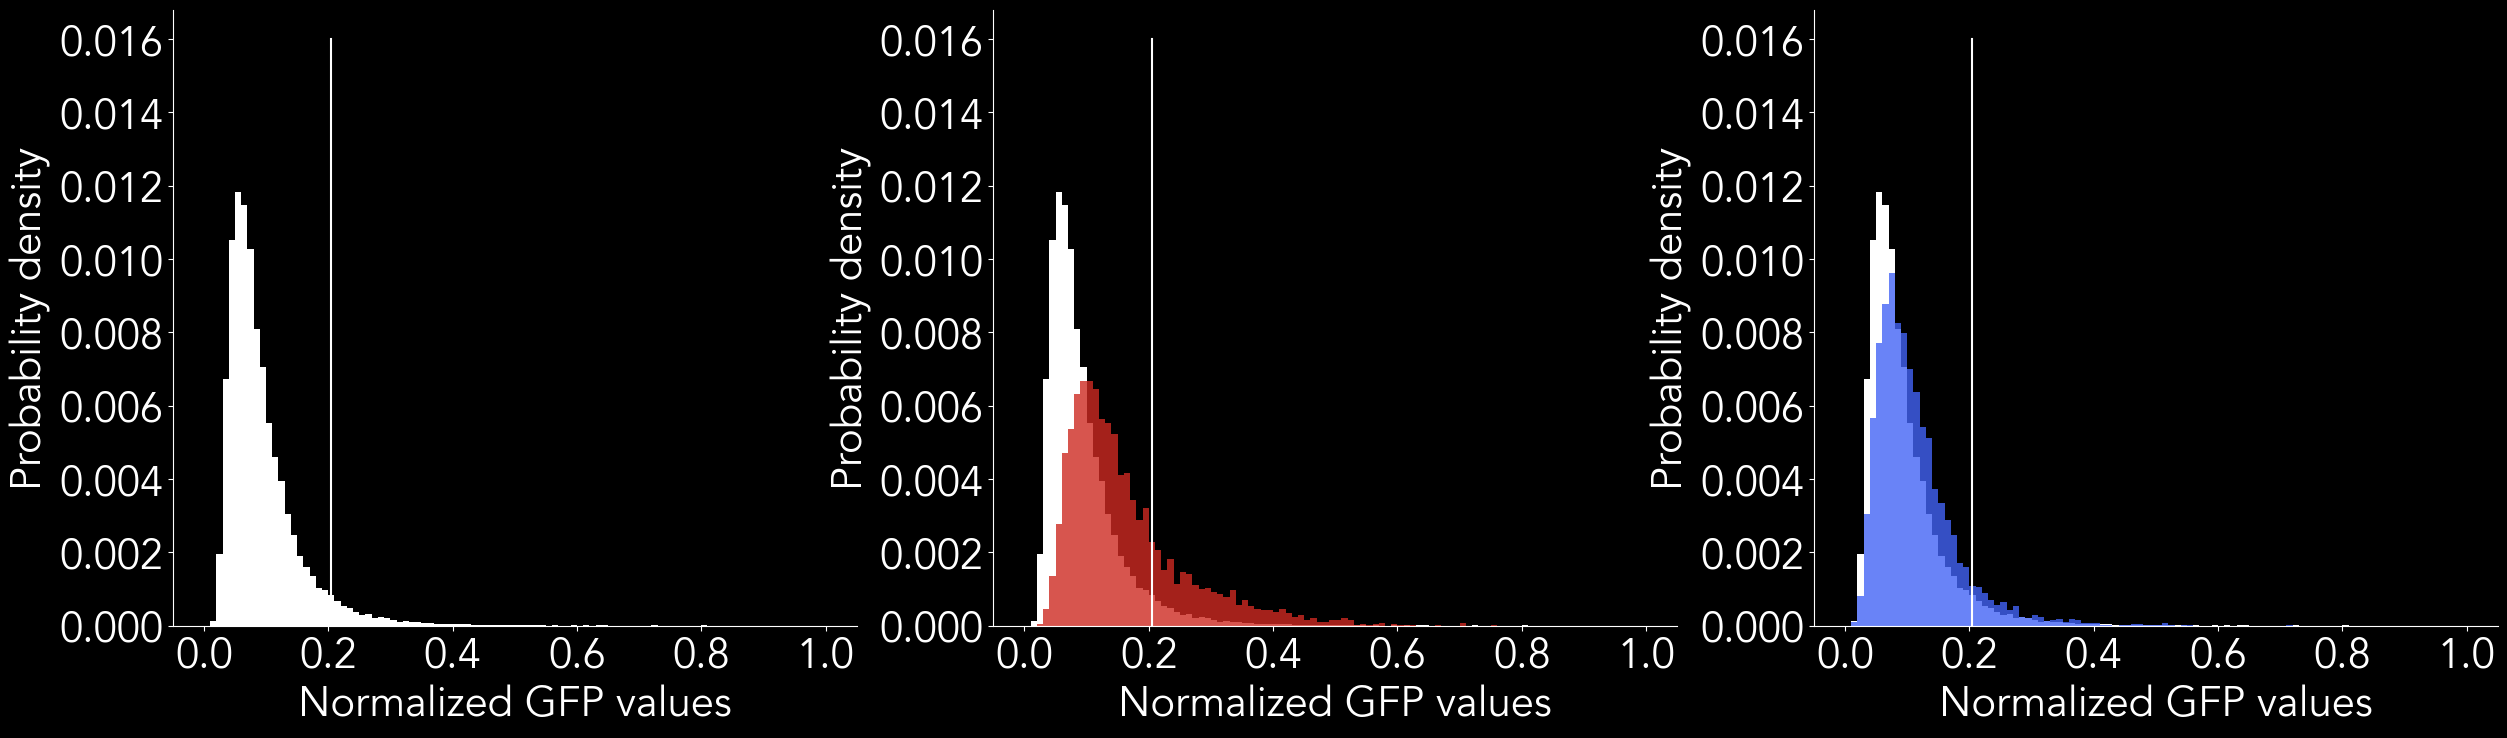

In [7]:


baseColor='#FFFFFF'
# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, (axH1,axH2,axH3) = plt.subplots(nrows=1, ncols=3, figsize=(30, 8))
axH1.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH3.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = 0.8)
axH3.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = 0.8)


axH1.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)
axH2.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)
axH3.plot([wt95CI,wt95CI],[0,0.016],color='white') #baseColor)


# axH.set_title('Distribution of GFP inside L cones')
for axH in (axH1,axH2,axH3):
    formatFigureMain(fH, axH, _)
    axH.set_xlabel('Normalized GFP values')
    if pdfV:
        axH.set_ylabel('Probability density')
    else:
        axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))


## Carinna's attempt at calculating fraction/percent of bright cells 

print('Percent bright (>{0:.4f}): wt={1:.2f}%, tbx2a={2:.2f}%, tbx2b={3:.2f}%'.format(wt95CI, 100*wGBright, 100*aGBright, 100*bGBright))



# cells of bright GFP cells: wt=4.602254312362707, tbx2a=22.675086107921928, tbx2b=7.314090019569472


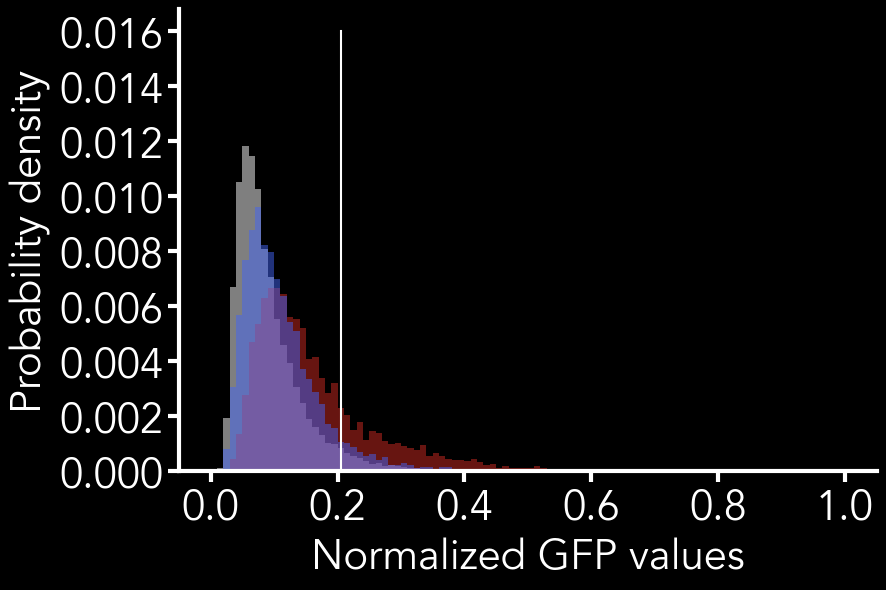

In [7]:

# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, axH = plt.subplots(nrows=1, ncols=1, figsize=(9, 6))


# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);


axH.stairs(wtH,wtB/1000, fill=True, color = 'white', alpha = .5)
axH.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = .5)
axH.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = .5)


axH.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)

formatFigureMain(fH, axH, _)
# axH.set_title('Distribution of GFP inside L cones')
axH.set_xlabel('Normalized GFP values')
if pdfV:
    axH.set_ylabel('Probability density')
else:
    axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# dPath = '/Users/angueyraaristjm/Documents/LiLab/Manuscripts/2021_zfConeRNAseq/resources/'
dPath = '/Users/angueyraaristjm/Documents/LiLab/Conferences/2021_RCS/resources/'
# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

## Plotting GFP in L cones 

Threshold (5%) is 0.205


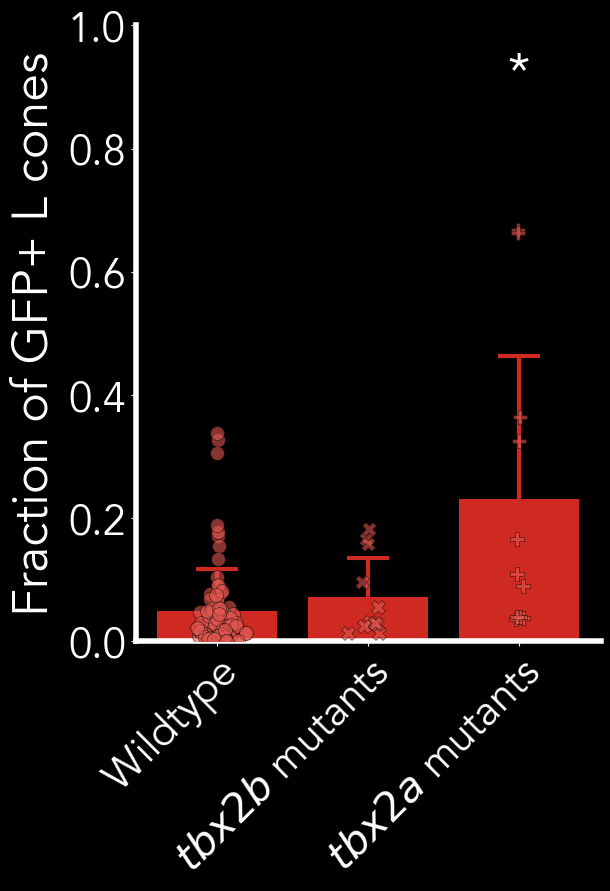

In [6]:
# collect all results


# analysis directory
dAnalysis = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"

#OpenFile

gene = 'wt'
wt_fPaths = [# '20250425_2ahetinx_5d_m2G_tdT_L08_002', #tear in retina 
                '20250425_2ahetinx_5d_m2G_tdT_L08_004',
                '20250425_2ahetinx_5d_m2G_tdT_L09_002',
                '20250425_2ahetinx_5d_m2G_tdT_L09_004',
                '20250425_2ahetinx_5d_m2G_tdT_L10_002',
                '20250425_2ahetinx_5d_m2G_tdT_L10_004',
                # '20250425_2ahetinx_5d_m2G_tdT_L11_002', too curved 
                '20250425_2ahetinx_5d_m2G_tdT_L12_002',
                # '20250425_2ahetinx_5d_m2G_tdT_L13_002', too curved 
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_002', #ISSUE
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L01_004', too curved 
                #'20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_002',  blurred 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L02_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L03_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L04_004',
                # '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_002', #ISSUE 
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L05_004',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L06_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_002',
                '20250425_5dpf_tbx2ahetinx_m2G_tdT_L07_004',
                '220250818_5d_2ahetinx_tdT_m2G_L01_002',
                '220250818_5d_2ahetinx_tdT_m2G_L02_002',
                '220250818_5d_2ahetinx_tdT_m2G_L03_002',
                 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
                '220250818_5d_2ahetinx_tdT_m2G_L05_004',
                '220250818_5d_2ahetinx_tdT_m2G_L06_002',
                '220250818_5d_2ahetinx_tdT_m2G_L07_002',
                '220250818_5d_2ahetinx_tdT_m2G_L08_002',
                '220250818_5d_2ahetinx_tdT_m2G_L08_004',
                '220250818_5d_2ahetinx_tdT_m2G_L010_002',
                '220250818_5d_2ahetinx_tdT_m2G_L011_002',
                '220250818_5d_2ahetinx_tdT_m2G_L011_006',
                # '220250817_5d_m2G_tdT_2ahetinx_L12_002', #mip not found
                '220250817_5d_m2G_tdT_2ahetinx_L12_006',
                '220250817_5d_m2G_tdT_2ahetinx_L13_002',
                '220250817_5d_m2G_tdT_2ahetinx_L14_002',
                '220250817_5d_m2G_tdT_2ahetinx_L14_006',
                # '220250723_2bhetinx_5d_tdT_m2G_L01_002',#no l seg curated
               # '220250723_2bhetinx_5d_tdT_m2G_L01_004', #no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_002',#no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L02_004',#no l seg curated
                '220250723_2bhetinx_5d_tdT_m2G_L03_002', 
                '220250723_2bhetinx_5d_tdT_m2G_L03_004',
                '220250723_2bhetinx_5d_tdT_m2G_L04_002',
                '220250723_2bhetinx_5d_tdT_m2G_L04_004',
                # '220250723_2bhetinx_5d_tdT_m2G_L06_002', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L06_004', #holes
                # '220250723_2bhetinx_5d_tdT_m2G_L08_002', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L08_004',
                '220250723_2bhetinx_5d_tdT_m2G_L09_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L09_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L13_002', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L14_002', #curved
                '220250723_2bhetinx_5d_tdT_m2G_L14_004', #position 38 
                # '220250723_2bhetinx_5d_tdT_m2G_L15_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_002', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L16_004', #curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L18_002',#curved
                # '220250723_2bhetinx_5d_tdT_m2G_L23_002', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L23_004', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L24_002', no l seg curated
                # '220250723_2bhetinx_5d_tdT_m2G_L25_002', #no m mip
                '220250723_2bhetinx_5d_tdT_m2G_L25_004',
                '20251017_5d_2bhetinx_tdT_m2G_L08_004',
                '20251017_5d_2bhetinx_tdT_m2G_L09_002',
                '20251017_5d_2bhetinx_tdT_m2G_L09_004',
                '20251017_5d_2bhetinx_tdT_m2G_L10_002',
                '20251017_5d_2bhetinx_tdT_m2G_L10_004',
                '20251017_5d_2bhetinx_tdT_m2G_L11_002',
                '20251017_5d_2bhetinx_tdT_m2G_L11_004',
                '20251017_5d_2bhetinx_tdT_m2G_L12_002', #high GFP? #position 47 
                '20251017_5d_2bhetinx_tdT_m2G_L12_004', # -34 - hgih gfp 
                '20251017_5d_2bhetinx_tdT_m2G_L14_002',
                '20251017_5d_2bhetinx_tdT_m2G_L14_004',
                '20251022_5d_2bhetinx_m2G_tdT_L01_002',
                '20251022_5d_2bhetinx_m2G_tdT_L01_004',
                '20251022_5d_2bhetinx_m2G_tdT_L02_002', #pos 53
                '20251022_5d_2bhetinx_m2G_tdT_L02_004', # -28? #high GFP 
                '20251022_5d_2bhetinx_m2G_tdT_L03_002',
                '20251022_5d_2bhetinx_m2G_tdT_L05_002',
                '20251022_5d_2bhetinx_m2G_tdT_L05_004',
                # '20251022_5d_2bhetinx_m2G_tdT_L06_002', #omit too curved :( 
                '20251022_5d_2bhetinx_m2G_tdT_L07_002',
                '20251022_5d_2bhetinx_m2G_tdT_L15_002',
                '20251022_5d_2bhetinx_m2G_tdT_L15_004',
                '20251022_5d_2bhetinx_m2G_tdT_L16_002',
                '20251022_5d_2bhetinx_m2G_tdT_L16_004',
                '20251022_5d_2bhetinx_m2G_tdT_L17_002',
                '20251022_5d_2bhetinx_m2G_tdT_L17_004',
                '20251022_5d_2bhetinx_m2G_tdT_L19_002',
                '20251022_5d_2bhetinx_m2G_tdT_L19_004',
                '20251022_5d_2bhetinx_m2G_tdT_L20_002',
                '20251022_5d_2bhetinx_m2G_tdT_L20_004',
                '20251022_5d_2bhetinx_m2G_tdT_L21_002',
                '20251022_5d_2bhetinx_m2G_tdT_L22_002',
                '20251022_5d_2bhetinx_m2G_tdT_L22_004',
                '20251022_5d_2bhetinx_m2G_tdT_L28_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L29_004_mip',
                '20251022_5d_tbx2bhetinx_m2G_tdT_L30_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L31_004', #redo GFP Quant Analysis 
                '20251022_5d_tbx2bhetinx_m2G_tdT_L35_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_002', #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L36_004', #MIP didn't save - COMEBACK?!?!
                '20251022_5d_tbx2bhetinx_m2G_tdT_L37_002', #  position 73 
                '20251022_5d_tbx2bhetinx_m2G_tdT_L39_002',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L40_002', #why is this high??? curved and does look like there is more GFP - Checked genotype - HET? OMIT? (position -5)
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_002',  
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L04_004',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_002',
                '20260226_5d_Tbx2ahetinx_tdT_m2G_L06_004',
                
         ]
# tbx2b
gene = 'Tbx2bKO';
tbx2b_fPaths = [ #PREVIOUS NTOES LOOKING AT THE GFP SCORES
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #HIGH - recheck 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #high - recheck 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', #HIGH - recheck raw data! 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002', #around 0.20
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #around 25% - recheck 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002', #checked - REALLY HIGH, curved zoom in - doesn't overlap - increase erosion?  
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004', #checked - doesn't overlap a lot - increase erosion?  
               

                '220250723_2bhetinx_5d_tdT_m2G_L07_002',
                # '220250723_2bhetinx_5d_tdT_m2G_L07_004', #curved -  omit from analyzed data (CH 2026)
                 # '220250723_2bhetinx_5d_tdT_m2G_L26_004', #no curated l seg
                '220250723_2bhetinx_5d_tdT_m2G_L26_002',
                '220250723_2bhetinx_5d_tdT_m2G_L27_002',
                '220250723_2bhetinx_5d_tdT_m2G_L28_002',
                '20251022_5d_2bhetinx_m2G_tdT_L24_002',
                '20251022_5d_2bhetinx_m2G_tdT_L24_004',
                '20251022_5d_2bhetinx_m2G_tdT_L26_002',
                '20251022_5d_2bhetinx_m2G_tdT_L26_004', #kinda curved 
                '20251022_5d_2bhetinx_m2G_tdT_L18_002',
                '20251022_5d_2bhetinx_m2G_tdT_L18_004',
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #curved and blurry -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_002',#too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L32_004', #too curved to analyze -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_002', # #redo GFP Quant Analysis 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L34_004', #too curved MIP - omit from analyzed data (CH 2026)  
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_002', # flat - high GFP score - rerun erosion after manual correcting 2.0 --> oversaturation of GFP, cones on side skewing resolution. 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L38_004', # curved -  omit from analyzed data (CH 2026)
                '20251022_5d_tbx2bhetinx_m2G_tdT_L41_002', #rerun erosion 
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L41_004', #curved - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_002',  #CURVED - stretched effect -  omit from analyzed data (CH 2026)
                # '20251022_5d_tbx2bhetinx_m2G_tdT_L42_004',  #CURVED - stretched effect -  omit from analyzed data (CH 2026)
               ]

# tbx2a
gene = 'Tbx2aKO';
tbx2a_fPaths = [
    '220250818_5d_2ahetinx_tdT_m2G_L04_002',
    '220250818_5d_2ahetinx_tdT_m2G_L09_002',
    '220250818_5d_2ahetinx_tdT_m2G_L09_006',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L01_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L02_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L03_004',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_002',
    '20260226_5d_Tbx2ahetinx_tdT_m2G_L05_004',
               ]

                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = 'wt'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     wtResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    wtResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

    
aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = 'Tbx2aKO'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     aResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    aResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = 'Tbx2bKO'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     bResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    bResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

# geneList = ['wt','Tbx2bKO', 'Tbx2aKO']
geneList = ['Wildtype', '$\it{tbx2b}$ mutants','$\it{tbx2a}$ mutants']


plotname = ''
fH, axH = plt.subplots(figsize= [6,8])

barW = np.size(geneList)+2; # bar width
barD = np.size(geneList)+1; # bar distance whitin 1 photoreceptor subtype
barP = -np.size(geneList)+1; # position in x-axis
barStep = 0.9; # distance between photoreceptor groups
barPos = []; #array to save bar positions

wtOrder = 1
jitter = estimateJitter(wtResults)/400
pH = plt.bar([barStep+wtOrder/barD], np.mean(wtResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+wtOrder/barD], np.mean(wtResults), yerr = [[0.025],[np.std(wtResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(wtResults))*[barStep+wtOrder/barD]+jitter, wtResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
# pH = plt.scatter([barStep+wtOrder/barD], wtResults[77], color=lighten_color(zfC['sws2'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6); #CHNAGE THINGY HERE!!!!!!!!!!!!!!!
barPos = np.append(barPos,(barStep+wtOrder/barD))

bOrder = 2
jitter = estimateJitter(bResults)/400
pH = plt.bar([barStep+bOrder/barD], np.mean(bResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+bOrder/barD], np.mean(bResults), yerr = [[0.025],[np.std(bResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(bResults))*[barStep+bOrder/barD]+jitter, bResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2b'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+bOrder/barD))

aOrder = 3
jitter = estimateJitter(aResults)/400
pH = plt.bar([barStep+aOrder/barD], np.mean(aResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+aOrder/barD], np.mean(aResults), yerr = [[0.025],[np.std(aResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(aResults))*[barStep+aOrder/barD]+jitter, aResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2a'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+aOrder/barD))

fontProps = formatFigureMain(fH, axH, pH)

# axH.set_ylabel('GFP+ L cones per 64 x 64 $\mu$m$^2$', fontproperties=formatFigureMain(fH, axH, pH))
# axH.set_ylim([0,180]);
# stath = 170


for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4) 

axH.set_ylabel('Fraction of GFP+ L cones', fontproperties=fontProps)
axH.set_ylim([0,1.0]);
stath = 0.9 #change height where sigf. star is


axH.xaxis.set_tick_params(rotation=45)
axH.set_xticks(np.sort(barPos));
axH.set_xticklabels(geneList,  ha='right', rotation_mode='anchor');

hH = plt.hlines(stath, barPos[0], barPos[1], colors='#000000',linewidth=4)
# plt.text((barPos[0]+barPos[1])/2, stath, '*', font_properties=fontProps, fontsize=36, ha='center')# plt.savefig(savePath + "Counts_tbx2_RU.svg", transparent=True, format="svg")
plt.text(barPos[2], stath, '*', font_properties=fontProps, fontsize=36, ha='center')


plt.style.use('dark_background') #Dark background
# plt.style.use('default')  # White background


print('Threshold (5%) is {0}'.format(wt95CI))

### Save as SVG to Google Drive/NAS

In [7]:

import os
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/Tbx2KO_UVRod/"
outdir = r"Y:/2026_TBX2Tornado/Fig3_Misexpression_LCones/DarkPanels"
# outdir = r"W:/2026_TBX2Tornado/Fig1_UVrod"

fname = f"Tbx2KOGFPQuant_LCones_dark.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


### Things to Pursue 
> Double positive L cones and create new segmentation of only those 
    > need to make all cells not above 95 CI threshold ==0 ()

Threshold (5%) is 0.205


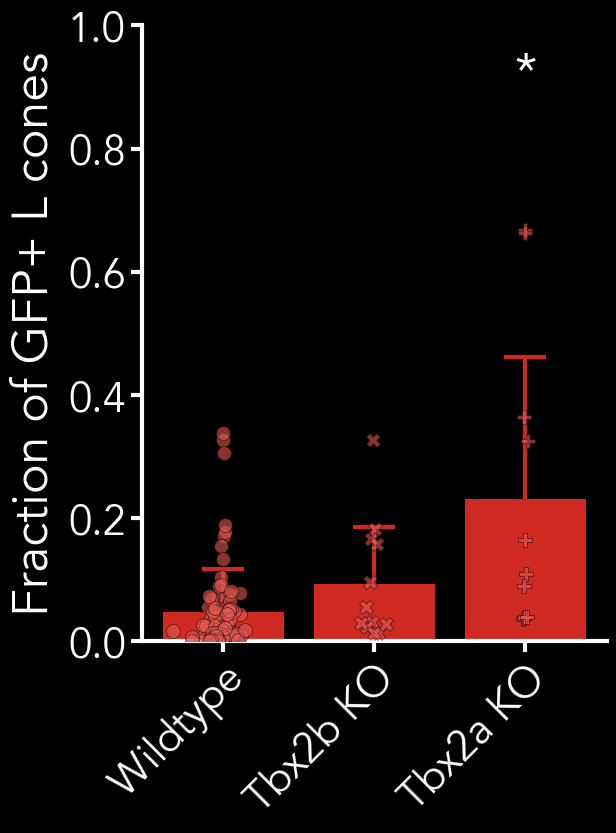

In [57]:

# geneList = ['wt','Tbx2bKO', 'Tbx2aKO']
geneList = ['Wildtype', 'Tbx2b KO','Tbx2a KO']


plotname = ''
fH, axH = plt.subplots(figsize= [6,8])

barW = np.size(geneList)+2; # bar width
barD = np.size(geneList)+1; # bar distance whitin 1 photoreceptor subtype
barP = -np.size(geneList)+1; # position in x-axis
barStep = 0.9; # distance between photoreceptor groups
barPos = []; #array to save bar positions

wtOrder = 1
jitter = estimateJitter(wtResults)/400
pH = plt.bar([barStep+wtOrder/barD], np.mean(wtResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+wtOrder/barD], np.mean(wtResults), yerr = [[0.025],[np.std(wtResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(wtResults))*[barStep+wtOrder/barD]+jitter, wtResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
# pH = plt.scatter([barStep+wtOrder/barD], wtResults[-34], color=lighten_color(zfC['sws2'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6); #CHNAGE THINGY HERE!!!!!!!!!!!!!!!
barPos = np.append(barPos,(barStep+wtOrder/barD))

bOrder = 2
jitter = estimateJitter(bResults)/400
pH = plt.bar([barStep+bOrder/barD], np.mean(bResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+bOrder/barD], np.mean(bResults), yerr = [[0.025],[np.std(bResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(bResults))*[barStep+bOrder/barD]+jitter, bResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2b'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
# pH = plt.scatter([barStep+bOrder/barD], bResults[10], color=lighten_color(zfC['sws2'],.75), zorder=8, marker = zfGm['tbx2b'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+bOrder/barD))

aOrder = 3
jitter = estimateJitter(aResults)/400
pH = plt.bar([barStep+aOrder/barD], np.mean(aResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+aOrder/barD], np.mean(aResults), yerr = [[0.028],[np.std(aResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(aResults))*[barStep+aOrder/barD]+jitter, aResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2a'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+aOrder/barD))

fontProps = formatFigureMain(fH, axH, pH)

# axH.set_ylabel('GFP+ L cones per 64 x 64 $\mu$m$^2$', fontproperties=formatFigureMain(fH, axH, pH))
# axH.set_ylim([0,180]);
# stath = 170

axH.set_ylabel('Fraction of GFP+ L cones', fontproperties=fontProps)
axH.set_ylim([0,1.0]);
stath = 0.9 #change height where sigf. star is


axH.xaxis.set_tick_params(rotation=45)
axH.set_xticks(np.sort(barPos));
axH.set_xticklabels(geneList,  ha='right', rotation_mode='anchor');

hH = plt.hlines(stath, barPos[0], barPos[1], colors='#000000',linewidth=4) #plot significance star 
# plt.text((barPos[0]+barPos[1])/2, stath, '*', font_properties=fontProps, fontsize=36, ha='center')# plt.savefig(savePath + "Counts_tbx2_RU.svg", transparent=True, format="svg")
plt.text(barPos[2], stath, '*', font_properties=fontProps, fontsize=36, ha='center')

plt.style.use('dark_background') #uncomment out for white background


# dPath = '/Users/angueyraaristjm/OneDrive - National Institutes of Health/zf/Manuscripts/2021_zfConeRNAseq/resources/'
# dPath = '/Users/angueyraaristjm/Documents/LiLab/Presentations/revealjs/resources/20211008_UCLA/'
# plt.savefig(dPath + "CRtbx2F0_GFPLcones.svg", transparent=True, format="svg")

print('Threshold (5%) is {0}'.format(wt95CI))

In [84]:
print(len(wtResults))
wtResults

80


[0.010050251256281407,
 0.008547008547008548,
 0.0473186119873817,
 0.13595166163141995,
 0.023391812865497075,
 0.04437869822485207,
 0.13709677419354838,
 0.06297229219143577,
 0.04381443298969072,
 0.03188405797101449,
 0.06306306306306306,
 0.0755813953488372,
 0.043010752688172046,
 0.031446540880503145,
 0.013513513513513514,
 0.02077922077922078,
 0.023936170212765957,
 0.0316622691292876,
 0.03937007874015748,
 0.06818181818181818,
 0.016666666666666666,
 0.03481012658227848,
 0.015625,
 0.03322259136212625,
 0.03278688524590164,
 0.04336734693877551,
 0.056818181818181816,
 0.12238805970149254,
 0.05144694533762058,
 0.010526315789473684,
 0.031746031746031744,
 0.002793296089385475,
 0.0,
 0.011730205278592375,
 0.02570694087403599,
 0.010471204188481676,
 0.005076142131979695,
 0.09164420485175202,
 0.0,
 0.049429657794676805,
 0.16756756756756758,
 0.16184971098265896,
 0.02127659574468085,
 0.03164556962025317,
 0.06925207756232687,
 0.0673854447439353,
 0.4046242774566474

## Save as SVG to NAS/G-Drive 
> Change filename! 

In [31]:
import os
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
outdir = r"W:/2026_TBX2Tornado/Fig2_Misexpression"
fname = f"TBX2KO_L_GFPQuant_3_nosig.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


## Stats

### Kruskal-Wallis

In [5]:
geneList = ['wt','Tbx2aKO','Tbx2bKO']
print('wt fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(wtResults)*100,np.std(wtResults)*100))
print('tbx2a fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(aResults)*100,np.std(aResults)*100))
print('tbx2b fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(bResults)*100,np.std(bResults)*100))
# Kruskal-Wallis test for repeated testing
H, p = kruskal(wtResults, aResults,bResults)
print('H = {0:.3f}, p = {1:.20f}, nEyes: wt = {2:.0f}; {3} = {4:.0f}; {5} = {6:.0f}'.format(H,p,len(wtResults),geneList[1],len(aResults),geneList[2],len(bResults)))
if p<0.01:
    r = scikit_posthocs.posthoc_conover([wtResults, aResults, bResults], p_adjust='Bonferroni')
    # r = scikit_posthocs.posthoc_conover([wtCount, aCount, bCount])
    print('\tConover-Iman posthoc + Bonferroni p adjustment:')
    print('\t\twt vs. {0}: p = {1:.20f} | p = {1}'.format(geneList[1],r.iloc[0,1]))
    print('\t\twt vs. {0}: p = {1:.20f} | p = {1}'.format(geneList[2],r.iloc[0,2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(geneList[1],geneList[2],r.iloc[1,2]))
    
    r = scikit_posthocs.posthoc_dunn([wtResults, aResults, bResults], p_adjust='Bonferroni')
    # r = scikit_posthocs.posthoc_conover([wtCount, aCount, bCount])
    print('\tDunn posthoc + Bonferroni p adjustment:')
    print('\t\twt vs. {0}: p = {1:.20f} | p = {1}'.format(geneList[1],r.iloc[0,1]))
    print('\t\twt vs. {0}: p = {1:.20f} | p = {1}'.format(geneList[2],r.iloc[0,2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}\n'.format(geneList[1],geneList[2],r.iloc[1,2]))

wt fractions:
	mean = 4.863%, s.d. = 6.84660%
tbx2a fractions:
	mean = 23.084%, s.d. = 23.17378%
tbx2b fractions:
	mean = 7.278%, s.d. = 6.31654%
H = 14.870, p = 0.00059019504192672290, nEyes: wt = 80; Tbx2aKO = 11; Tbx2bKO = 11
	Conover-Iman posthoc + Bonferroni p adjustment:
		wt vs. Tbx2aKO: p = 0.00055722323760218026 | p = 0.0005572232376021803
		wt vs. Tbx2bKO: p = 0.19078446262249193488 | p = 0.19078446262249193
		Tbx2aKO vs. Tbx2bKO: p = 0.39948426628983108033 | p = 0.3994842662898311
	Dunn posthoc + Bonferroni p adjustment:
		wt vs. Tbx2aKO: p = 0.00087491279396138919 | p = 0.0008749127939613892
		wt vs. Tbx2bKO: p = 0.24042816648056308804 | p = 0.2404281664805631
		Tbx2aKO vs. Tbx2bKO: p = 0.47354048288684258416 | p = 0.4735404828868426



### Mann-Whitney

In [ ]:
print('wt fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(wtResults)*100,np.std(wtResults)*100))
print('tbx2a fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(aResults)*100,np.std(aResults)*100))
print('tbx2b fractions:')
print('\tmean = {0:.3f}%, s.d. = {1:.5f}%'.format(np.mean(bResults)*100,np.std(bResults)*100))
# Mann Whitney 
Au, pA = mannwhitneyu(wtResults, aResults)
print('wt vs. tbx2a:')
print('\tU = {0:.3f}, p = {1:.5f}'.format(Au,pA))
Bu, pB = mannwhitneyu(wtResults, bResults)
print('wt vs. tbx2b:')
print('\tU = {0:.3f}, p = {1:.5f}'.format(Bu,pB))

### Kruskal Wallis on GFP positive L cones 

In [ ]:
### STATS on GFP positive L Cones
import os
import numpy as np
from scipy.stats import kruskal
import scikit_posthocs as sp

# --- inputs you already have ---
dAnalysis = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/"
rName = "lGtile"
thr = wt95CI * 1000  # keep consistent with your plotting code

# wt_fPaths, tbx2b_fPaths, tbx2a_fPaths must already be defined above

# --- helpers ---
def per_eye_fraction_from_npz(npz_path, key, thr):
    results = np.load(npz_path)
    x = np.asarray(results[key], dtype=float)
    x = x[~np.isnan(x)]
    if x.size == 0:
        return np.nan
    return np.count_nonzero(x > thr) / x.size

def collect_group(fpaths, gene_folder):
    vals = []
    missing = []
    for fPath in fpaths:
        npz_path = os.path.join(dAnalysis, gene_folder, fPath, "quantificationGFP.npz")
        if not os.path.exists(npz_path):
            missing.append(npz_path)
            continue
        vals.append(per_eye_fraction_from_npz(npz_path, rName, thr))
    vals = np.asarray(vals, dtype=float)
    vals = vals[~np.isnan(vals)]
    return vals, missing

# --- collect per-eye summaries ---
wt_per_eye, wt_missing = collect_group(wt_fPaths, "wt")
tbx2b_per_eye, tbx2b_missing = collect_group(tbx2b_fPaths, "Tbx2bKO")
tbx2a_per_eye, tbx2a_missing = collect_group(tbx2a_fPaths, "Tbx2aKO")

print("Per-eye n:", len(wt_per_eye), len(tbx2b_per_eye), len(tbx2a_per_eye))
print("Per-eye means:", np.mean(wt_per_eye), np.mean(tbx2b_per_eye), np.mean(tbx2a_per_eye))
print("Per-eye medians:", np.median(wt_per_eye), np.median(tbx2b_per_eye), np.median(tbx2a_per_eye))

# optional: report missing files (so you know if you silently dropped eyes)
if wt_missing or tbx2b_missing or tbx2a_missing:
    print("\nMissing npz files:")
    for p in wt_missing[:5]: print("  wt:", p)
    for p in tbx2b_missing[:5]: print("  Tbx2bKO:", p)
    for p in tbx2a_missing[:5]: print("  Tbx2aKO:", p)
    if len(wt_missing) + len(tbx2b_missing) + len(tbx2a_missing) > 15:
        print("  ... (more missing not shown)")

# --- stats ---
h, p = kruskal(wt_per_eye, tbx2b_per_eye, tbx2a_per_eye)
print(f"\nKruskal–Wallis on per-eye fractions ({rName} > thr):")
print(f"  H = {h:.3f}, p = {p:.3e}")

r = sp.posthoc_conover([wt_per_eye, tbx2b_per_eye, tbx2a_per_eye], p_adjust="bonferroni")
r.index = ["wt", "tbx2b_KO", "tbx2a_KO"]
r.columns = ["wt", "tbx2b_KO", "tbx2a_KO"]

print("\nConover-Iman posthoc + Bonferroni:")
print(r)

print("\nPairwise p-values:")
print(f"  wt vs tbx2b_KO:  {r.loc['wt','tbx2b_KO']:.3e}")
print(f"  wt vs tbx2a_KO:  {r.loc['wt','tbx2a_KO']:.3e}")
print(f"  tbx2b_KO vs tbx2a_KO: {r.loc['tbx2b_KO','tbx2a_KO']:.3e}")